# v6b analysis A (GPU 0): mixed model + ReDo run, matched pairs, chance level, does the self come back
**Run All.** About 1.5 hours. Analysis B (GPU 1) runs at the same time. At the end: push the results (last cell).

In [2]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def run(*cmd):
    p = subprocess.Popen([sys.executable, "-u", *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

MIXED, REDO = "v6b_mixed_s0", "v6b_cont_redo_from60"
for r in [MIXED, REDO]:
    print(r, "checkpoints:", len(glob.glob(f"runs/{r}/ckpt/p*.pt")))

v6b_mixed_s0 checkpoints: 61
v6b_cont_redo_from60 checkpoints: 31


In [3]:
# all checkpoints these analyses need (downloads what is missing)
need = json.loads(subprocess.check_output([sys.executable, "analysis_v6c.py", "--list"]))
for r, phs in need.items():
    get(r, phs)
print("ok")

ok


## 1. Analysis pass on the two new runs (~16 s per checkpoint)

In [4]:
for r in [MIXED, REDO]:
    run("analysis_v5_compute.py", "--run", r, "--gpu", GPU)

v6b_mixed_s0: 61 checkpoints -> /workspace/shreshth/analysis/v5/v6b_mixed_s0
  phase   0 (init) done in 15s | ETA 15 min
  phase   1 (mix) done in 23s | ETA 19 min
  phase   2 (mix) done in 16s | ETA 17 min
  phase   3 (mix) done in 15s | ETA 16 min
  phase   4 (mix) done in 15s | ETA 16 min
  phase   5 (mix) done in 15s | ETA 15 min
  phase   6 (mix) done in 15s | ETA 15 min
  phase   7 (mix) done in 15s | ETA 14 min
  phase   8 (mix) done in 15s | ETA 14 min
  phase   9 (mix) done in 15s | ETA 14 min
  phase  10 (mix) done in 15s | ETA 13 min
  phase  11 (mix) done in 15s | ETA 13 min
  phase  12 (mix) done in 15s | ETA 13 min
  phase  13 (mix) done in 15s | ETA 12 min
  phase  14 (mix) done in 15s | ETA 12 min
  phase  15 (mix) done in 15s | ETA 12 min
  phase  16 (mix) done in 15s | ETA 11 min
  phase  17 (mix) done in 15s | ETA 11 min
  phase  18 (mix) done in 15s | ETA 11 min
  phase  19 (mix) done in 15s | ETA 11 min
  phase  20 (mix) done in 15s | ETA 10 min
  phase  21 (mix) d

## 2. Training curves, matched-movement pairs (now with the mixed model), chance level on many checkpoints, does the same self come back

In [5]:
run("analysis_v6c.py", "--gpu", GPU, "--parts", "training", "pairs", "noise", "selfreturn", "--tag", "A")

analysis_v6c | cont v4b_continual_s0 | hi v4b_only_hi_s0 | mixed v6b_mixed_s0 | redo v6b_cont_redo_from60 | push v6_hi_push0.6_from30 | phase 45 | tau 0.2 | parts ['training', 'pairs', 'noise', 'selfreturn']

=== TRAINING: mixed model and ReDo run vs the references ===
  v4b_continual_s0               phases 0..86
  v4b_only_hi_s0                 phases 0..90
  v6b_mixed_s0                   phases 0..60
  v6b_cont_redo_from60           phases 60..90
  v6_cont_noise0.0007_from60     phases 60..86
  v4b_continual_s0               phase 61 (hi): chrF on it 51.7 | rarely active None
  v4b_continual_s0               phase 70 (hi): chrF on it 50.3 | rarely active None
  v4b_continual_s0               phase 80 (zh): chrF on it 20.1 | rarely active None
  v4b_continual_s0               phase 86 (zh): chrF on it 17.2 | rarely active None
  v6_cont_noise0.0007_from60     phase 61 (hi): chrF on it 51.4 | rarely active 0.1481
  v6_cont_noise0.0007_from60     phase 70 (hi): chrF on it 49.9 | rarel

## 3. Summary table and figures for every run (relative gap vs chance, size-matched self, 95% intervals)

In [6]:
run("analyze_v6.py")
print(open("analysis/v6/summary.txt").read())

runs found: ['continual (ref)', 'Hindi only (ref)', 'v6_cont_noise0.0007_from60', 'v6b_cont_redo_from60', 'v6_hi_push0.6_from30', 'v6b_mixed_s0']
  continual (ref): done
  Hindi only (ref): done
  v6_cont_noise0.0007_from60: done
  v6b_cont_redo_from60: done
  v6_hi_push0.6_from30: done
  v6b_mixed_s0: done
self = biggest group of MLP neurons. fixed: tau 0.2 for every layer. sized: per checkpoint, tau where the biggest group = 40% of the layer.
One number per switch = mean over the 8 MLP layers; table = mean over switches in the window (switch counted by its to_phase).
rel gap = (task - self)/task, from the window means. excess = rel gap minus pure noise of the same size on the same kind of network
(continual curve for continual + fix runs, Hindi curve for Hindi + push runs). [..] = 95% bootstrap interval over switches.

===== self: fixed =====
run                                           window   n   task   self  rel gap          [95%]  excess          [95%]  size  stays   IoU
contin

analysis/v6/v6c_A/training_mixed.png


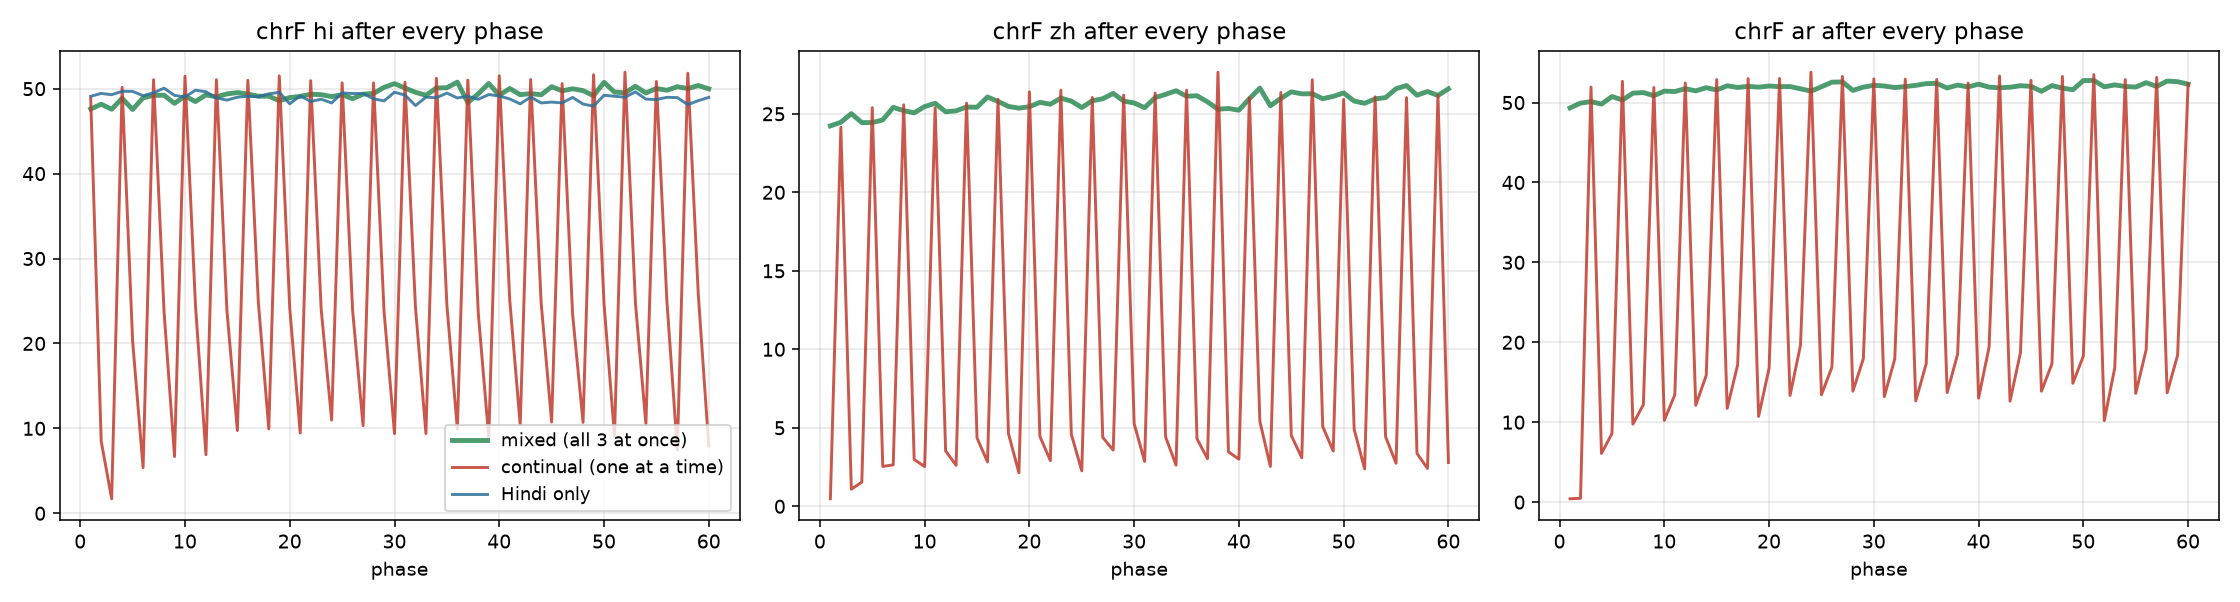

analysis/v6/v6c_A/training_redo.png


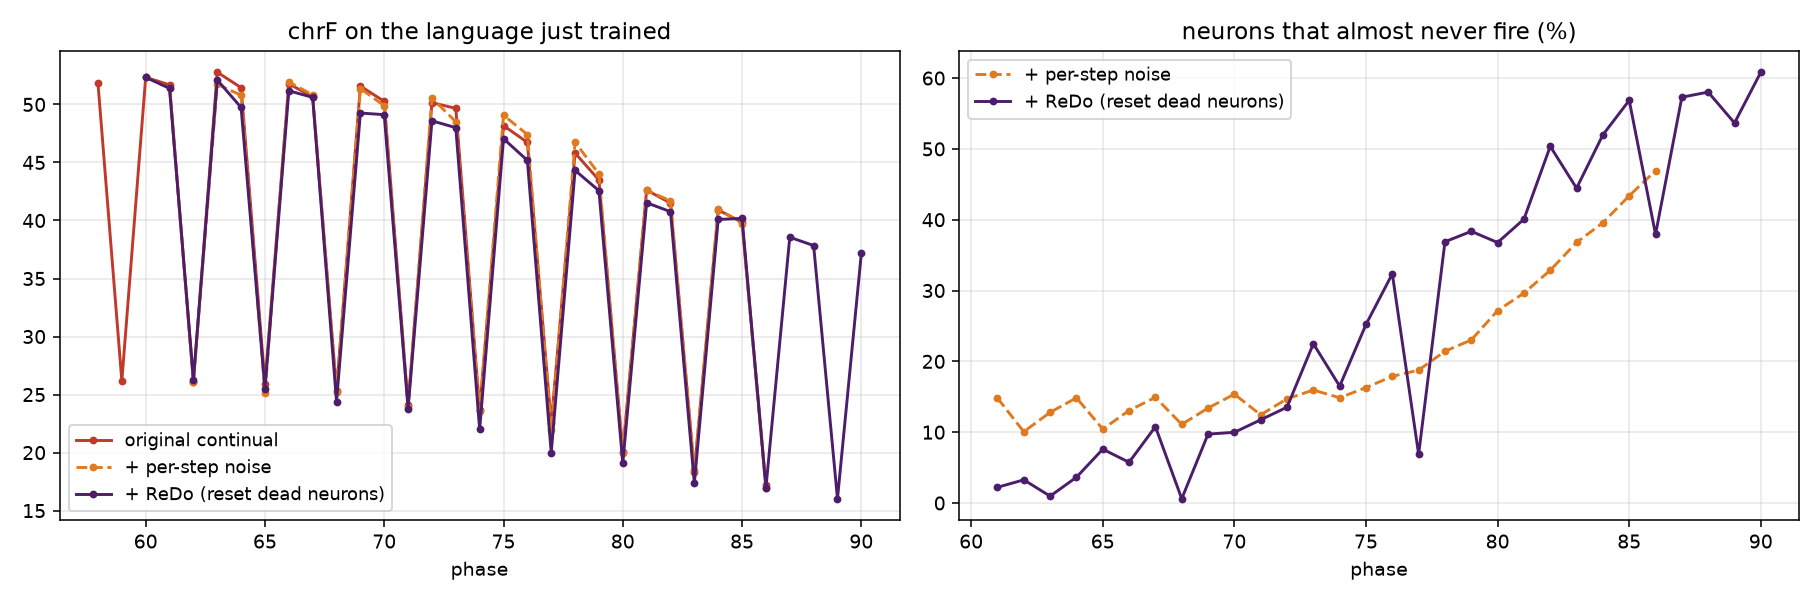

analysis/v6/v6c_A/pairs.png


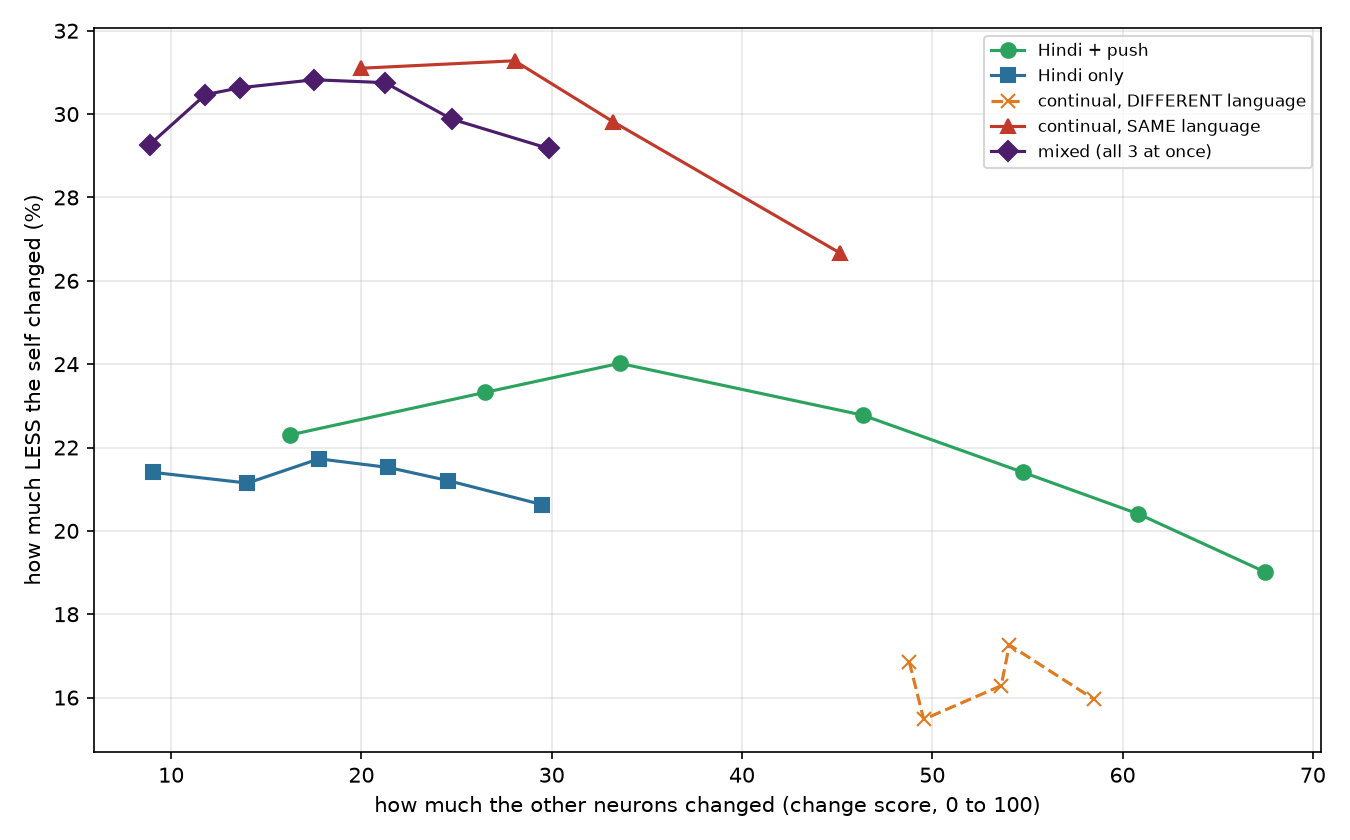

analysis/v6/v6c_A/noise.png


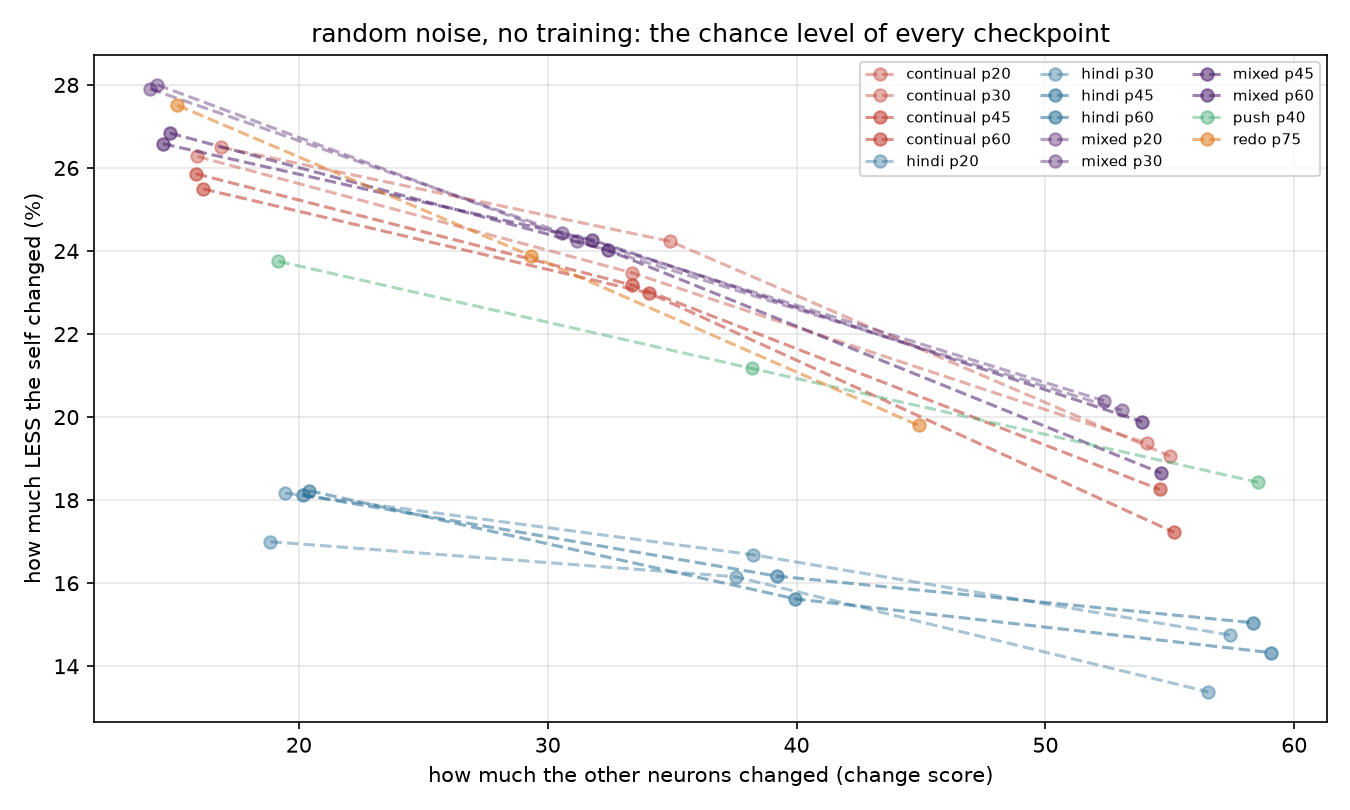

analysis/v6/v6c_A/selfreturn.png


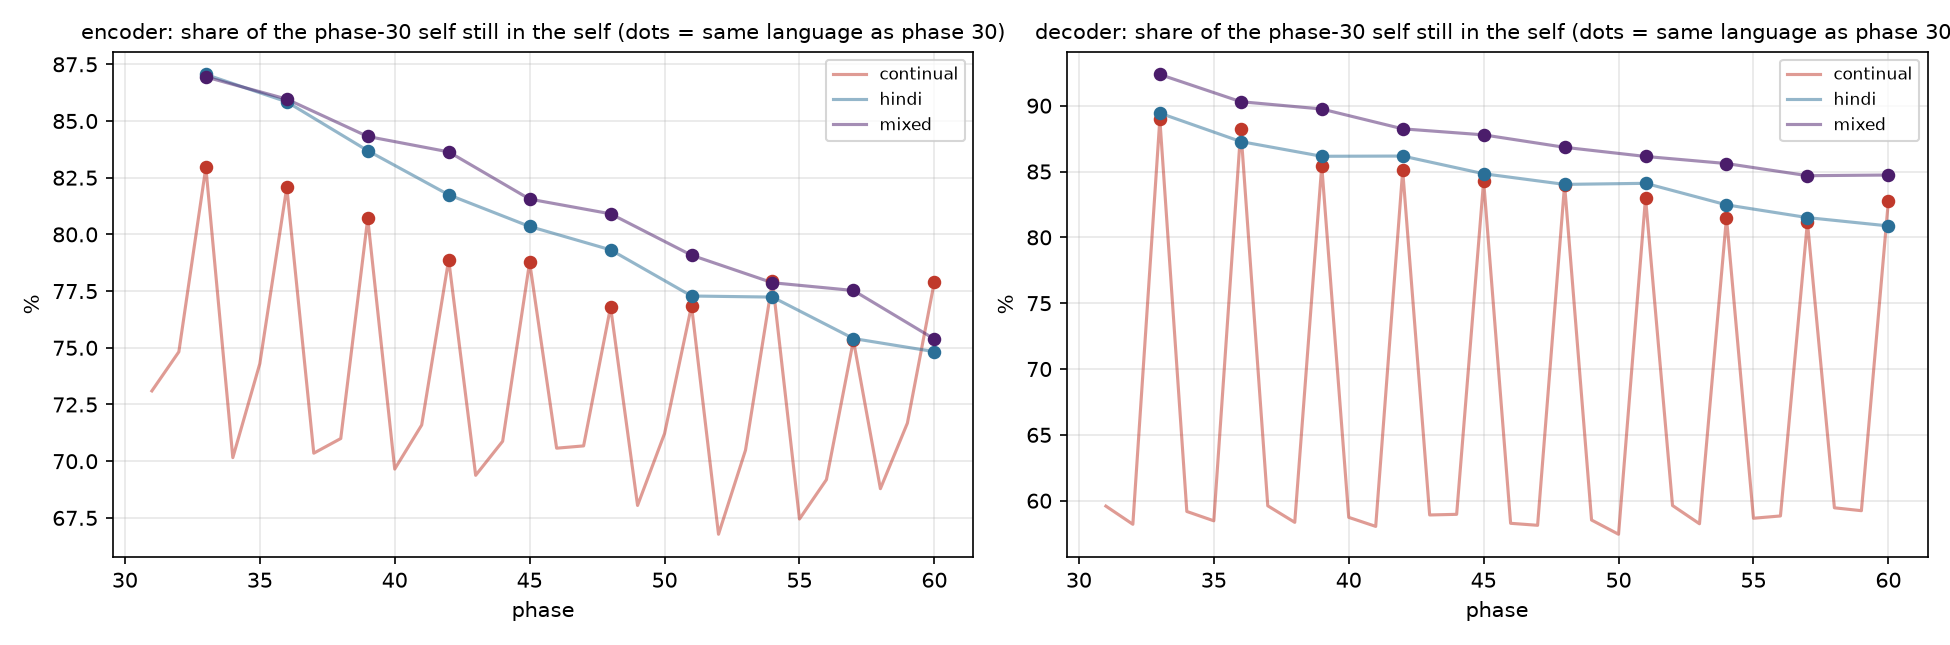

analysis/v6/A_q2_movement_vs_gap.png


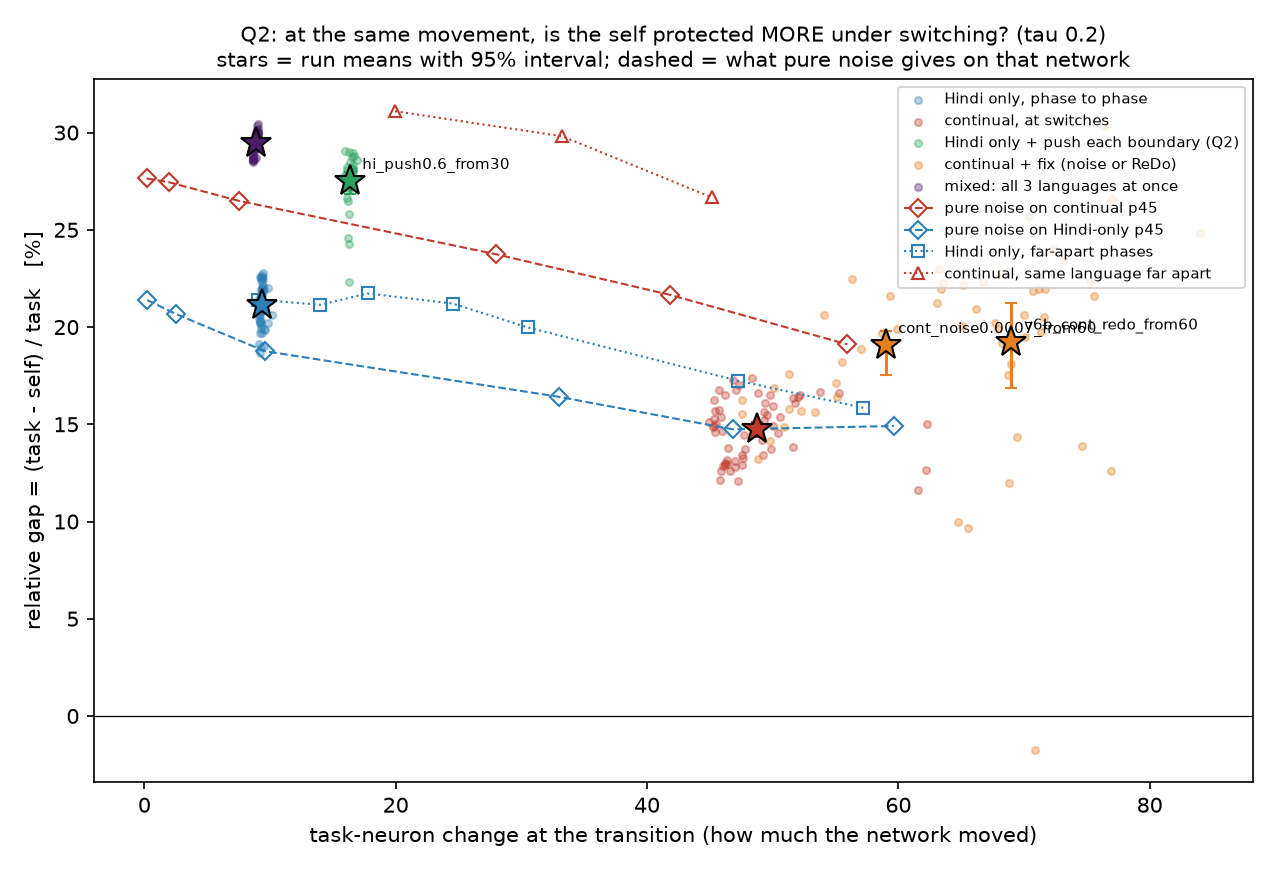

analysis/v6/C_health.png


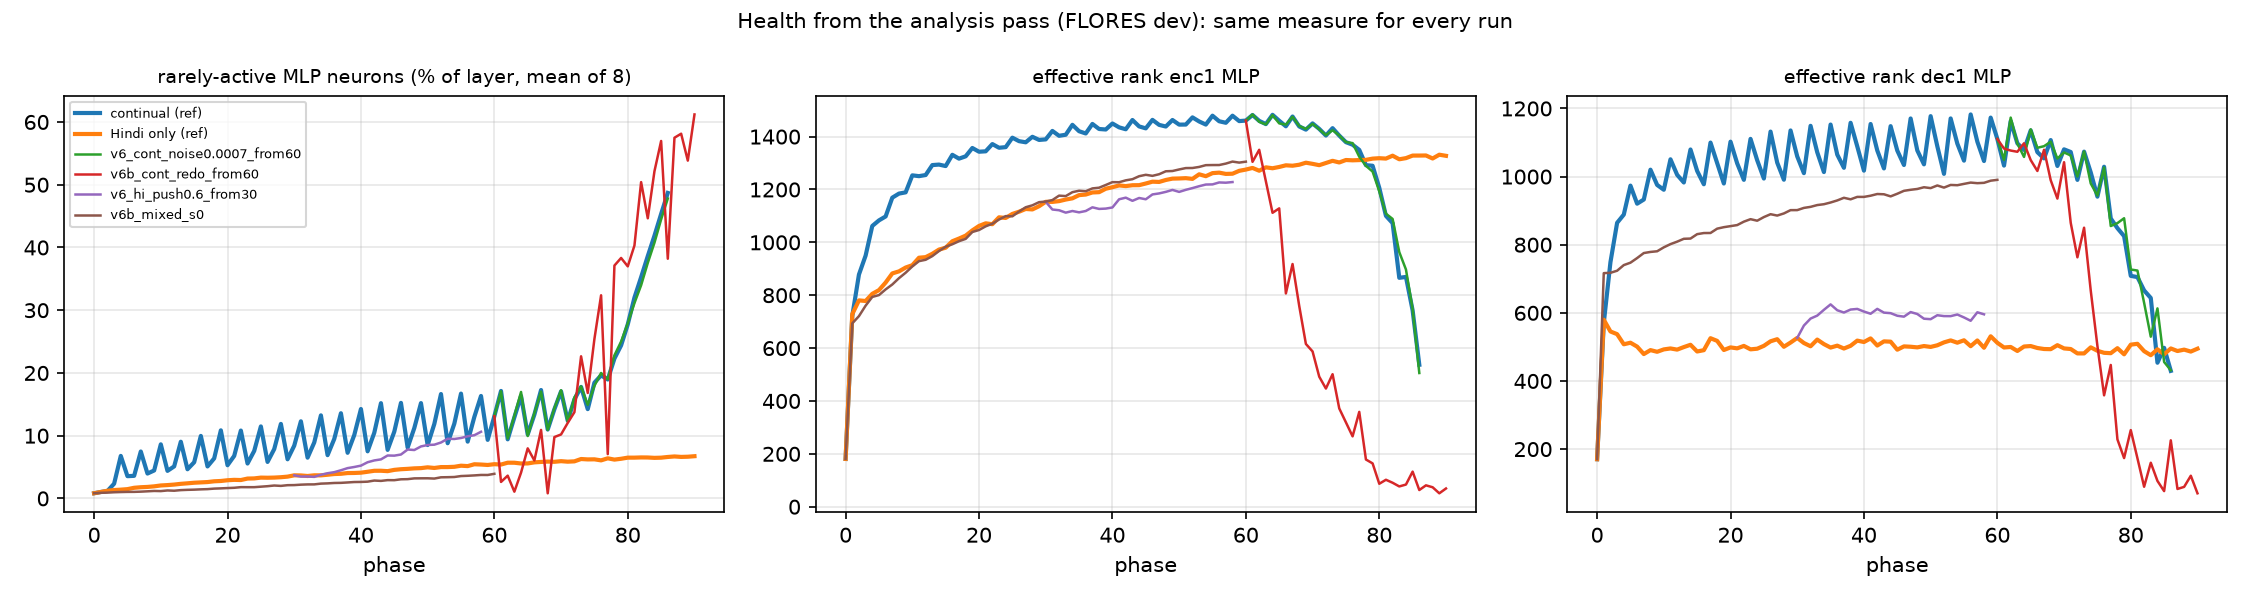

In [7]:
for f in ["analysis/v6/v6c_A/training_mixed.png", "analysis/v6/v6c_A/training_redo.png", "analysis/v6/v6c_A/pairs.png",
          "analysis/v6/v6c_A/noise.png", "analysis/v6/v6c_A/selfreturn.png", "analysis/v6/A_q2_movement_vs_gap.png", "analysis/v6/C_health.png"]:
    if os.path.exists(f):
        print(f); display(Image(f))

## 4. Push the results (run after BOTH notebooks are done; save both notebooks first: Ctrl+S)
Pushes the small result files and both executed notebooks to GitHub (branch v6), and the new checkpoints to HF.

In [ ]:
os.system("git checkout v6 2>/dev/null || git checkout -b v6")
os.system("git add -f analysis/v6 analysis_v6b_A_gpu0.ipynb analysis_v6b_B_gpu1.ipynb analysis_v6c.py analyze_v6.py common_v6.py "
          "train_v6b_MIXED_gpu0.ipynb train_v6b_REDO_gpu1.ipynb runs/v6b_mixed_s0/phases.jsonl runs/v6b_cont_redo_from60/phases.jsonl")
os.system('git commit -m "v6b: mixed + ReDo runs, analysis outputs"')
os.system("git push origin v6")
for r in [MIXED, REDO]:
    api.upload_folder(repo_id=HF_REPO, folder_path=f"runs/{r}", path_in_repo=r)   # checkpoints to HF (skips files already there)
print("done")